# 02 - Feature exploration

Inspect the generated 184-feature table, compare distributions between classes, and visualize correlations and feature separability.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
FEATURES_PATH = ROOT / 'data' / 'processed' / 'features.csv'
METADATA_PATH = ROOT / 'data' / 'processed' / 'feature_metadata.json'
features = pd.read_csv(FEATURES_PATH)
metadata = json.loads(METADATA_PATH.read_text(encoding='utf-8'))
features.head()

,track_id,label,mfcc_1_mean,mfcc_1_std,mfcc_1_min,mfcc_1_max,mfcc_2_mean,mfcc_2_std,mfcc_2_min,mfcc_2_max,...,rms_1_min,rms_1_max,spectral_flatness_1_mean,spectral_flatness_1_std,spectral_flatness_1_min,spectral_flatness_1_max,tempo,duration_seconds,sample_rate,rms_energy
0,000657be-98fe-4f4c-9b00-461ea2079938,ai_generated,-284.129245,86.415079,-608.060364,-122.077232,104.899308,48.844536,-45.666626,191.560547,...,0.000724,0.150489,0.014211,0.040189,0.000010,0.308692,99.384014,30.0,22050.0,0.004470
1,0010ccca-4088-4975-9bd4-9b2985851f32,ai_generated,-213.402314,97.715446,-597.078735,-2.420801,86.410739,47.266767,-58.983459,181.761353,...,0.000016,0.172840,0.013922,0.032686,0.000006,0.472061,143.554688,30.0,22050.0,0.009201
2,0017a515-cb61-4ffc-8336-f4ef8cd6668f,ai_generated,-236.037983,86.583005,-579.426025,-44.043045,102.477890,42.297707,-29.832350,172.131577,...,0.000007,0.199950,0.018907,0.046069,0.000015,0.449174,161.499023,30.0,22050.0,0.005653
3,00206f12-4f96-45f2-bd12-45240b3789ab,ai_generated,-109.083074,70.944757,-580.971985,-12.222078,65.849952,25.781186,-47.636383,138.598877,...,0.000020,0.205560,0.030319,0.035018,0.000060,0.388791,89.102909,30.0,22050.0,0.015369
4,002fb2bd-0d98-455b-90c0-b9db06838764,ai_generated,-223.263677,79.275362,-397.679413,-22.488359,98.540387,37.070193,-1.499669,176.595306,...,0.011589,0.198099,0.018386,0.028343,0.000080,0.170580,151.999081,30.0,22050.0,0.003884


In [2]:
print(f"Rows: {len(features)}")
print(f"Features: {len(metadata['feature_columns'])}")
display(features.dtypes.value_counts())
display(features.groupby('label').size().to_frame('count'))
display(features.isna().sum().sort_values(ascending=False).head())

Rows: 440
Features: 184


float64    184
object       2
Name: count, dtype: int64

,count
label,
ai_generated,220
human,220


track_id          0
chroma_12_std     0
chroma_10_mean    0
chroma_10_std     0
chroma_10_min     0
dtype: int64

In [3]:
numeric_features = metadata['feature_columns']
summary = features.groupby('label')[numeric_features].mean().T
summary['absolute_difference'] = (summary['ai_generated'] - summary['human']).abs()
summary.sort_values('absolute_difference', ascending=False).head(20)

label,ai_generated,human,absolute_difference
spectral_rolloff_1_mean,4577.783455,3222.815140,1354.968315
spectral_centroid_1_max,5978.489484,4751.884185,1226.605299
spectral_rolloff_1_max,9230.305398,8217.315008,1012.990390
spectral_centroid_1_mean,2185.809253,1615.651116,570.158137
spectral_bandwidth_1_mean,2305.000139,1774.142712,530.857426
spectral_bandwidth_1_max,3736.833627,3357.548680,379.284948
spectral_rolloff_1_std,1884.736146,1544.507043,340.229103
spectral_bandwidth_1_min,972.753389,770.213266,202.540123
spectral_centroid_1_std,918.024052,745.635352,172.388700
spectral_centroid_1_min,563.125877,472.344119,90.781758


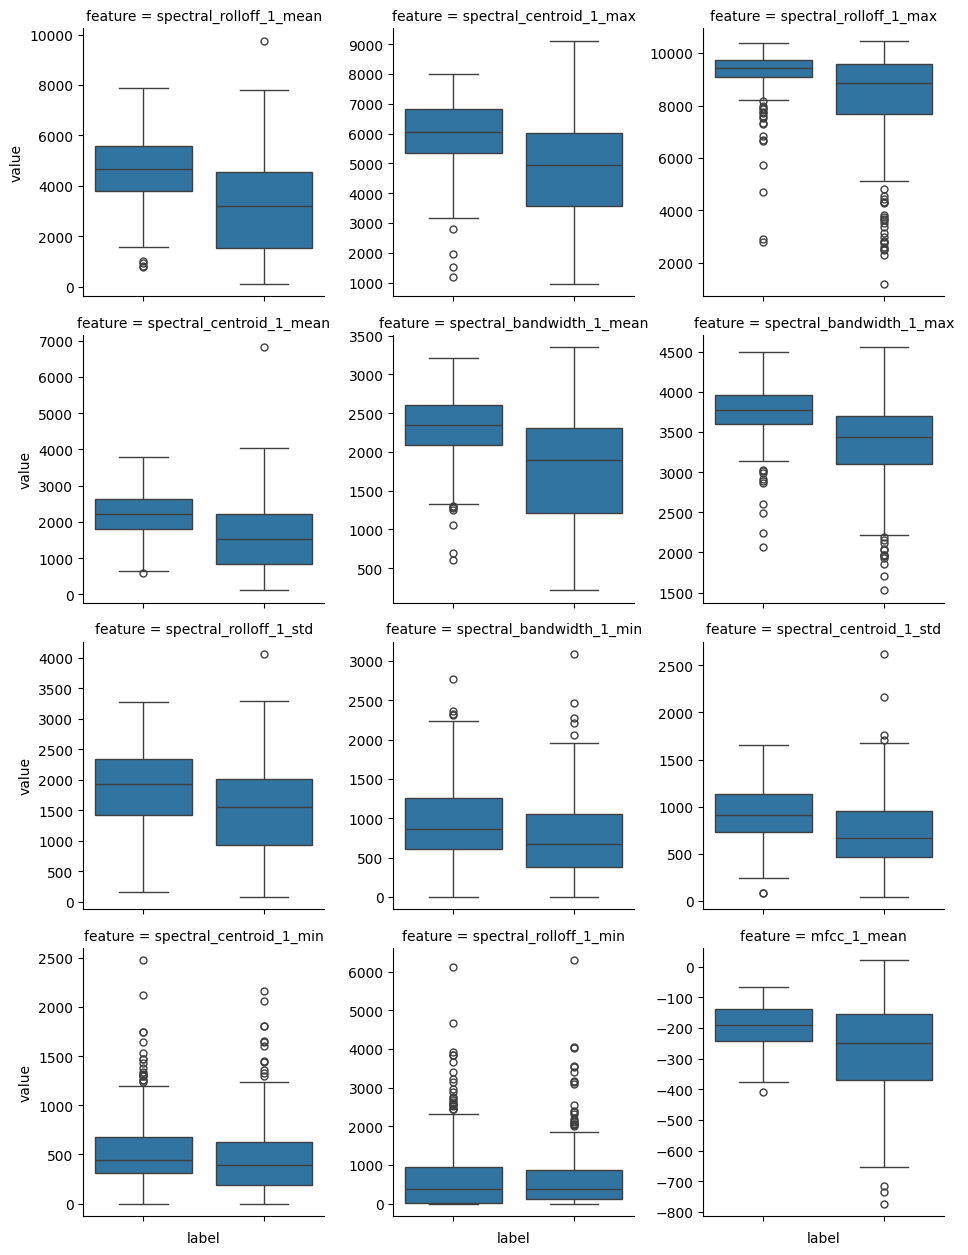

In [4]:
top_features = summary.sort_values('absolute_difference', ascending=False).head(12).index
long = features[['label', *top_features]].melt(id_vars='label', var_name='feature', value_name='value')
g = sns.catplot(data=long, x='label', y='value', col='feature', col_wrap=3, kind='box',
                sharey=False, height=3.2)
g.set_xticklabels(rotation=25)
plt.show()

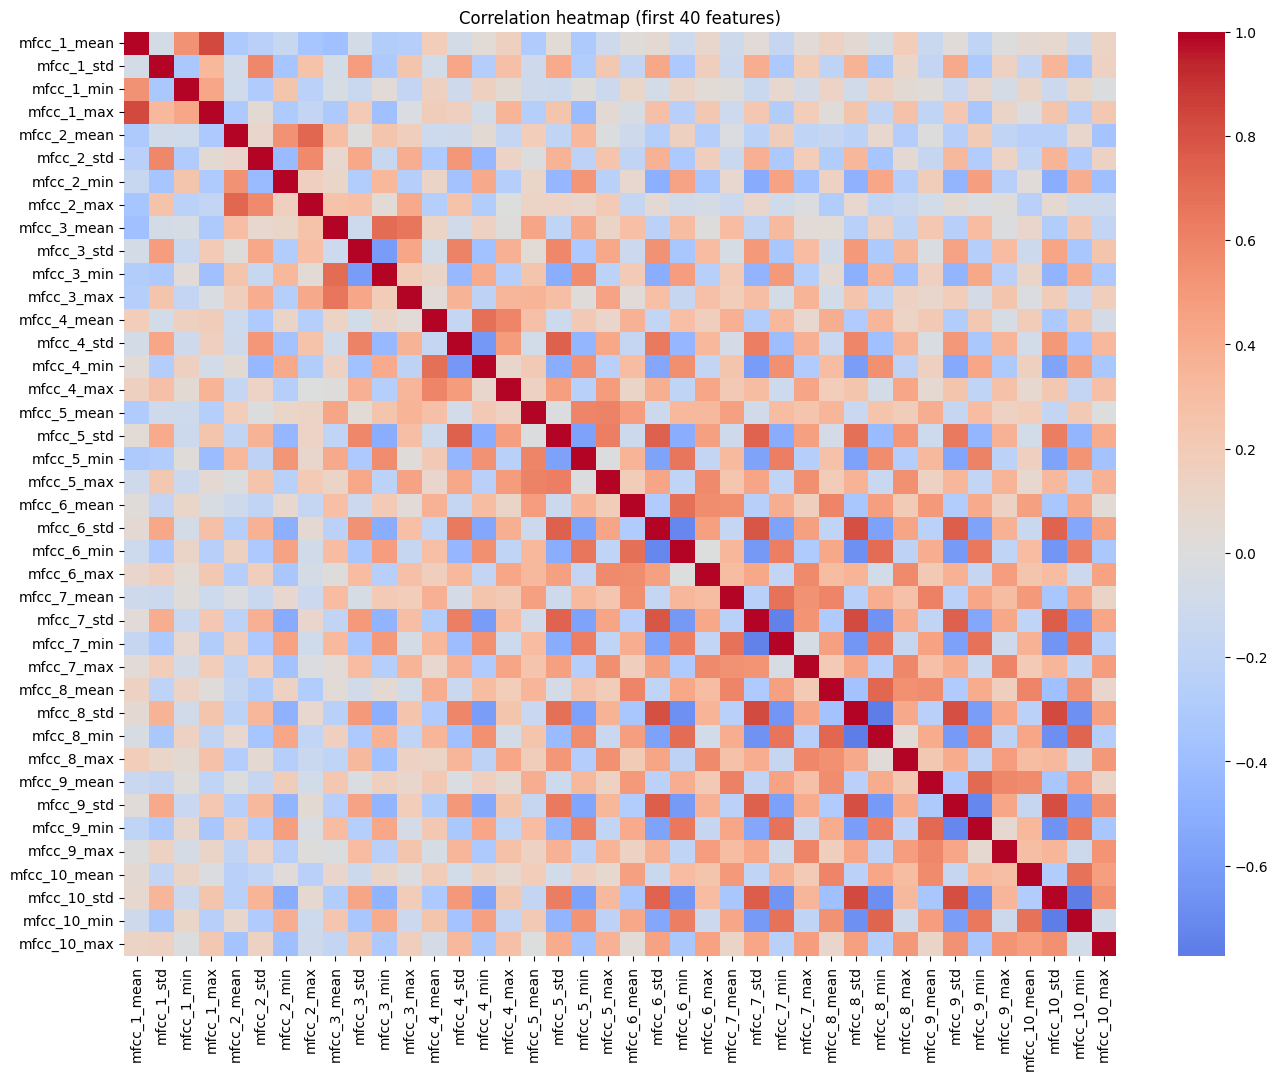

In [5]:
corr = features[numeric_features].corr()
plt.figure(figsize=(16, 12))
sns.heatmap(corr.iloc[:40, :40], cmap='coolwarm', center=0)
plt.title('Correlation heatmap (first 40 features)')
plt.show()